# 1D Unsteady Heat Conduction Implicit March
### Midterm Takehome Assignment
Juliano B12202031

✅ **Submission requirement:** complete source code

Complete source code (frozen for this assignment): [github.com/anojewel/siefdi/tree/midterm](https://github.com/anojewel/siefdi/tree/midterm)

In [30]:
%load_ext autoreload
%autoreload 2

import numpy as np
import inspect
import matplotlib.pyplot as plt

from src.geometry import RectangleSpace, CellCentredGrid
from src.fields import InternalScalarField, SimpleWallBC
from src.matrix_solver import SystemLinearEquations
from src.fvm import Diffusion, Transient, ImplicitMarch, ExplicitMarch  

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Problem statement

A thin plate is initially at a uniform temperature of $200\,{}^\circ\mathrm{C}$. At a certain time $t = 0\,\mathrm{s}$ the temperature of the east side of the plate is suddenly reduced to $0\,{}^\circ\mathrm{C}$. The other side of the surface is insulated. Use the **fully implicit finite volume method** with time step sizes ($\Delta t = 2\,\mathrm{s}, 4\,\mathrm{s}, \text{and } 8\,\mathrm{s}$) to calculate the transient temperature distribution of this slab and compare with the analytical solution at time (i) $t = 40\,\mathrm{s}$, (ii) $t = 80\,\mathrm{s}$ and (iii) $t = 120\,\mathrm{s}$

Length of the plate is $L = 2\,\mathrm{cm}$, thermal conductivity of this rod is $= \dfrac{10\,\mathrm{W}}{\mathrm{mK}}$, $\rho c = 10 \times \dfrac{10^6\,\mathrm{J}}{\mathrm{m^3 K}}$

The one dimensional transient heat conduction problem is governed by
$$ \rho c \frac{\partial T}{\partial t} = \frac{\partial}{\partial x}\left(k \frac{dT}{dx}\right) $$

The analytical solution is given in Ozisik (1985) as
$$ \frac{T(x,t)}{200} = \frac{4}{\pi} \sum_{n=1}^{\infty} \frac{(-1)^{n+1}}{2n-1} \exp\left(-\alpha \lambda_n^2 t\right) \cos\left(\lambda_n x\right) $$
$$ \lambda_n = \frac{(2n-1)\pi}{2L}, \quad \alpha = \frac{k}{\rho c} $$

Please also compare the explicit and implicit method solutions for a time step of $8\,\mathrm{s}$.

We make the 1D rod using syntax similar to Assignment 1.

In [31]:
# L = 2cm and mesh, limit it to 5 nodes so it's easier to read:
rod_gridded = RectangleSpace([[0,0.02],[0,0.1],[0,0.1]]).grid('cell',[5])
# Insulated west wall plus the east wall held 0:
heated_ends = SimpleWallBC(
    wall_values = [[0,0],[0,0],[0,0]],
    derivative_order= [[1,0],[1,1],[1,1]]
)
rod_temp = InternalScalarField(
    grid=rod_gridded,
    bcs=heated_ends,
    values=200 * np.ones(rod_gridded.shape[0])
)
# Store the diffusion term, k= 10 is stored here
rod_diffusion_term = Diffusion(rod_temp, 10)

**Index convention.** Nodes (cell centres) get whole-number indices: $T_i$ is the temperature at node $x_i$, the centre of cell $i$. Faces sit halfway between nodes and get half indices: cell $i$ spans from its west face $x_{i-1/2}$ to its east face $x_{i+1/2}$.

Two different lengths follow from this:
- $\Delta x = x_{i+1/2} - x_{i-1/2}$: face to face, the width of cell $i$.
- $(\delta x)_{i+1/2} = x_{i+1} - x_i$: node to node, the distance across face $i+1/2$. At a wall it is only half a cell.
- $\Delta V = A\,\Delta x$: the volume of cell $i$, with $A$ the cross-section area of the rod.

$T_0$ and $T_{N+1}$ are the wall values, located on the wall faces $x_{1/2}$ and $x_{N+1/2}$; the half-cell distance is in $D_{1/2}$ and $D_{N+1/2}$.

These values are stored in the modules of the `Grid` in `geometry.py`. `[0]` to just show the $x$ dimension:

In [32]:
print("faces   x_{i±1/2}:", rod_gridded.faces[0])
print("nodes   x_i      :", rod_gridded.centres[0])
print("δx      (centre_spacing):", rod_gridded.centre_spacing[0])
print("Δx      (cell_lengths)  :", rod_gridded.cell_lengths[0])

faces   x_{i±1/2}: [0.    0.004 0.008 0.012 0.016 0.02 ]
nodes   x_i      : [0.002 0.006 0.01  0.014 0.018]
δx      (centre_spacing): [0.002 0.004 0.004 0.004 0.004 0.002]
Δx      (cell_lengths)  : 0.004


### Governing equation

✅ **Submission requirement:** governing-equation derivation and analytical solution

We take a thin slice of the plate between $x$ and $x+dx$, with cross-section area $A$. There is no heat source inside, so energy conservation says the rate of change of the energy stored in the slice equals the heat flowing in minus the heat flowing out:
$$ \frac{\partial}{\partial t}\left(\rho c\,T\,A\,dx\right) = q(x)\,A - q(x+dx)\,A $$
where $q$ is the heat flux in the $+x$ direction. $\rho c$, $A$ and $dx$ are constant, so they come out of the time derivative. Taylor expanding $q(x+dx) \approx q(x) + \dfrac{\partial q}{\partial x}dx$:
$$ \rho c \frac{\partial T}{\partial t} A\,dx = -\frac{\partial q}{\partial x} A\,dx \implies \rho c \frac{\partial T}{\partial t} = -\frac{\partial q}{\partial x} $$
Fourier's law relates the flux to the temperature gradient (heat flows from hot to cold, hence the minus sign):
$$ q = -k\frac{\partial T}{\partial x} $$
Substituting it in:
$$ \rho c \frac{\partial T}{\partial t} = \frac{\partial}{\partial x}\left(k \frac{\partial T}{\partial x}\right) $$
which is the governing equation given in the problem.

### Analytical solution

✅ **Submission requirement:** governing-equation derivation and analytical solution

The analytical solution solves the same governing equation with the same boundary and initial conditions as our numerical problem:
$$ \rho c \frac{\partial T}{\partial t} = \frac{\partial}{\partial x}\left(k \frac{\partial T}{\partial x}\right), \qquad \left(\frac{\partial T}{\partial x}\right)_{x=0} = 0, \qquad T(L,t) = 0, \qquad T(x,0) = 200 $$
It is found by separation of variables, $T(x,t) = X(x)\,\Theta(t)$. The insulated wall at $x = 0$ only allows cosine modes $\cos(\lambda_n x)$, the cold wall $T(L,t) = 0$ fixes $\lambda_n$, each mode decays in time as $\exp(-\alpha\lambda_n^2 t)$, and the initial temperature of $200\,{}^\circ\mathrm{C}$ fixes the coefficients. The result, from Ozisik (1985), is
$$ \frac{T(x,t)}{200} = \frac{4}{\pi} \sum_{n=1}^{\infty} \frac{(-1)^{n+1}}{2n-1} \exp\left(-\alpha \lambda_n^2 t\right) \cos\left(\lambda_n x\right), \qquad \lambda_n = \frac{(2n-1)\pi}{2L}, \qquad \alpha = \frac{k}{\rho c} $$
Note that $x = 0$ is the insulated wall and $x = L$ is the cold wall, the same as our grid. The series can't be summed to infinity, so we stop at $100$ terms. This is far more than needed: the $\exp(-\alpha\lambda_n^2 t)$ factor shrinks very fast with $n$, so for $t \ge 40\,\mathrm{s}$ every term past $n \approx 10$ is negligible.

✅ **Submission requirement:** control-volume discretization

Now we begin the discretization. We integrate over each finite volume, from the west face $x_{i-1/2}$ to the east face $x_{i+1/2}$ of cell $i$ (the diffusion coefficient and the cross-section area $A$ are constant).

$$ \rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = kA \left[ \left(\frac{\partial T}{\partial x}\right)_{i+1/2} - \left(\frac{\partial T}{\partial x}\right)_{i-1/2} \right]$$


Use central difference assuming piecewise-linear profile $\left(\frac{\partial T}{\partial x}\right)_{i+1/2} \approx \frac{T_{i+1} - T_i}{(\delta x)_{i+1/2}}$:
$$ \rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = kA\left[ \frac{T_{i+1} - T_i}{x_{i+1}- x_i} - \frac{T_i - T_{i-1}}{x_i - x_{i-1}}\right ] $$
$$ \rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = kA \left[ \frac{T_{i+1}}{(\delta x)_{i+1/2}} +\frac{T_{i-1}}{(\delta x)_{i-1/2}} - T_i \left( \frac {1}{(\delta x)_{i-1/2}} +\frac{1}{(\delta x)_{i+1/2}}\right)\right]$$


FVM rule assumes that $T$ is constant over each grid (face to face):
$$\rho c A \int_{x_{i-1/2}}^{x_{i+1/2}} \frac{\partial T}{\partial t} dx' = \rho c \frac{\partial T_i}{\partial t} A\,(x_{i+1/2}-x_{i-1/2}) =\rho c \frac{\partial T_i}{\partial t} \Delta V $$
$$\implies \rho c \frac{\partial T_i}{\partial t} \Delta V = kA \left[ \frac{T_{i+1}}{(\delta x)_{i+1/2}} +\frac{T_{i-1}}{(\delta x)_{i-1/2}} - T_i \left( \frac {1}{(\delta x)_{i-1/2}} +\frac{1}{(\delta x)_{i+1/2}}\right)\right]$$

Now define the face conductances:
$$
D_{i\pm1/2} = \frac{kA}{(\delta x)_{i\pm1/2}}
$$

$D_i$ is stored in `Diffusion.conductances`.

In [34]:
print(inspect.getsource(Diffusion.conductances))

    def conductances(self):
        """🤖 [CLAUDE] Diffusion conductance D = Γ·A/δx of every face, per axis.

        Returns:
            list[np.ndarray]: One array per axis with N+1 entries for N cells,
            laid out like ``grid.centre_spacing``. Entry ``i`` belongs to face
            ``i``: the first and last are wall faces (δx is half a cell), and
            the rest are interior faces (δx is centre to centre).
        """
        target_list = []
        g = self.field.grid
        for axis in range(g.dim):
            ### ↓ THE FORMULA ↓ ###
            singledim_diffusion_conductances = (self.coefficient * g.areas[axis]) * (1/g.centre_spacing[axis])
            target_list.append(singledim_diffusion_conductances)
        return target_list



In [35]:
print(f"D_i face conductances: {rod_diffusion_term.conductances()[0]}")

D_i face conductances: [50. 25. 25. 25. 25. 50.]


On the uniform grid ($\Delta x = 4\,\mathrm{mm}$, $A = 0.01\,\mathrm{m^2}$) these are the numbers printed above:

$$
D_{0.5} = D_{5.5} = \frac{kA}{\Delta x/2} = 50\,\mathrm{W/K}, \qquad
D_{1.5} = D_{2.5} = D_{3.5} = D_{4.5} = \frac{kA}{\Delta x} = 25\,\mathrm{W/K}
$$

The two wall faces are twice as large because the wall is only half a cell from its node.

The equation becomes:
$$\rho c\,\Delta V\,\frac{\partial T_i}{\partial t} = D_{i+1/2}T_{i+1} + D_{i-1/2}T_{i-1} - (D_{i-1/2}+D_{i+1/2})\,T_i$$

We cannot yet build a square matrix out of this before taking a look at the walls. First for Neumann BCS, the problem states that the west wall is insulated ($\partial_x T = 0$). But to maintain generalization for the code, I won't substitute $0$ here.

 Thus, at the west face:
$$ \left(\frac{\partial T}{\partial x}\right)_{0.5} = \frac{T_1 - T_{0}}{(\delta x)_{0.5}} \implies T_{1} - T_0 = \left(\frac{\partial T}{\partial x}\right)_{0.5} (\delta x)_{0.5}$$


Thus, for the first equation ($i=1$)
$$
\begin{aligned}
\rho c \Delta V \dfrac{\partial T_1}{\partial t}&=D_{1.5}T_{2} + D_{0.5}T_{0} -(D_{0.5} + D_{1.5}) T_1\\
&=D_{1.5}T_2 + D_{0.5}(T_{0} - T_1) -D_{1.5} T_1\\
&=D_{1.5}T_2 -D_{0.5 }\left(\frac{\partial T}{\partial x}\right)_{0.5} (\delta x)_{0.5} - D_{1.5} T_1
\end{aligned}
$$
Since $D_{0.5}(\delta x)_{0.5} = \dfrac{kA}{(\delta x)_{0.5}}(\delta x)_{0.5} = kA$, the wall term is just Fourier's law, the heat flowing into cell 1 through the west wall:
$$ -D_{0.5}\left(\frac{\partial T}{\partial x}\right)_{0.5}(\delta x)_{0.5} = -kA\left(\frac{\partial T}{\partial x}\right)_{0.5} $$
For the insulated wall the slope is $0$, so this term vanishes.

$T_0$ has dropped out, so the equation involves only the unknowns $T_1$ and $T_2$. This is one step toward building the square matrix.

The next one is the Dirichlet BCS for the east wall $T_6 = 0$. To maintain generalization, I don't substitute the number. 

For the last equation ($i=5$):
$$
\begin{aligned}
\rho c \Delta V \frac{\partial T_5}{\partial t} &= D_{5.5} T_{6} + D_{4.5}T_4 - (D_{4.5}+D_{5.5})T_5
\end{aligned}
$$
Since $T_6$ is known, $D_{5.5}T_6$ moves into $\vec b$, and the remaining terms involve only the unknowns $T_4$ and $T_5$. This means our $5\times5$ square matrix is ready to be built:


Writing all five equations together:
$$
\rho c\,\Delta V \frac{d}{dt}
\underbrace{\begin{bmatrix} T_1 \\ T_2 \\ T_3 \\ T_4 \\ T_5 \end{bmatrix}}_{\vec{T}}
= -\underbrace{
\begin{bmatrix}
\color{#4493f8} D_{1.5} & \color{#4493f8} -D_{1.5} & \color{#4493f8} 0 & \color{#4493f8} 0 & \color{#4493f8} 0 \\
-D_{1.5} & D_{1.5}+D_{2.5} & -D_{2.5} & 0 & 0 \\
0 & -D_{2.5} & D_{2.5}+D_{3.5} & -D_{3.5} & 0 \\
0 & 0 & -D_{3.5} & D_{3.5}+D_{4.5} & -D_{4.5} \\
\color{#4493f8} 0 & \color{#4493f8} 0 & \color{#4493f8} 0 & \color{#4493f8} -D_{4.5} & \color{#4493f8} D_{4.5}+D_{5.5}
\end{bmatrix}}_{\mathbf A}
\underbrace{\begin{bmatrix} T_1 \\ T_2 \\ T_3 \\ T_4 \\ T_5 \end{bmatrix}}_{\vec{T}}
+ \underbrace{
\begin{bmatrix} \color{#4493f8} -D_{0.5}\left(\frac{\partial T}{\partial x}\right)_{0.5}(\delta x)_{0.5} \\ 0 \\ 0 \\ 0 \\ \color{#4493f8} D_{5.5}\,T_6 \end{bmatrix}}_{\vec b}
$$

The whole right-hand side comes from the diffusion term, so both $\mathbf A$ and $\vec b$ are built by `Diffusion`: `matrix()` gives $\mathbf A$ and `source_vector()` gives $\vec b$. The Neumann boudnary condition modifications are also in here.

In [36]:
print(inspect.getsource(Diffusion.matrix))
print(inspect.getsource(Diffusion.source_vector))

    def matrix(self):
        ### A. Assemble A matrix
        # 1. Take the list for just one dimensional diffusion conductances (x-direction)
        diffconds_1d = self.conductances()[0]
        
        # 2. Make diagonal with A_{ii} = D_{i} + D_{i+1}
        matrix_diagonal = np.diag([diffconds_1d[i] + diffconds_1d[i+1] for i in range(len(diffconds_1d)-1)])

        # 3. Make off diagonal parts
        matrix_up_offdiag = np.diag([-diffconds_1d[i+1] for i in range(len(diffconds_1d)-2)],1)
    
        # 4. Combine them to get our target matrix (our result A)
        A= matrix_diagonal + matrix_up_offdiag + matrix_up_offdiag.T

        # 5. Check for Neumann
        f = self.field
        if f.bcs.derivative_order[0,0] == 1:
            A[0,0] = diffconds_1d[1]
        if f.bcs.derivative_order[0,1] == 1:
            A[-1,-1] = diffconds_1d[-2]

        return A

    def source_vector(self):
        diffconds_1d = self.conductances()[0]
        ### B. Assemble b vector
        # Ge

In [37]:
A = rod_diffusion_term.matrix()
b = rod_diffusion_term.source_vector()
print("A =\n", A)
print("b =", b)

A =
 [[ 25. -25.   0.   0.   0.]
 [-25.  50. -25.   0.   0.]
 [  0. -25.  50. -25.   0.]
 [  0.   0. -25.  50. -25.]
 [  0.   0.   0. -25.  75.]]
b = [-0.  0.  0.  0.  0.]


The whole thing can now be written simply as:
$$\rho c\,\Delta V\,\frac{d\vec{T}}{dt} = -\mathbf{A}\,\vec{T} + \vec{b}$$

Up until now is just a copy from Assignment 3 in `1d_rod_unsteady.ipynb`. Integrating both sides.
$$\int_t^{t+\Delta t} \rho c\,\Delta V\,\frac{d\vec{T}}{dt} dt=\int_t^{t+\Delta t} -\mathbf{A}\,\vec{T} + \vec{b} \, dt $$

- Transient field is stored in `Transient.field`
- $\rho c$ is stored in `Transient.coefficient`

In [38]:
print(inspect.signature(Transient))
# The numbers here
rod_transient_term = Transient(
    field = rod_temp,
    coefficient = 10**7 # From the Problem Statement.
)

(field, coefficient)


- $\Delta V$ is stored in `CellCentredGrid.volume`. Since the grid is uniform, every cell has the same volume $\Delta V = \Delta x\,\Delta y\,\Delta z$.

In [39]:
print(inspect.getsource(CellCentredGrid.volume.func))
print(f"ΔV = {rod_gridded.volume}")

    @cached_property
    def volume(self):
        ### 8. VOLUMES (every cell has the same volume on a uniform grid)
        return np.prod(self.cell_lengths)

ΔV = 4e-05


With $\Delta x = 4\,\mathrm{mm}$ and $A = 0.01\,\mathrm{m^2}$ we get $\Delta V = 4 \times 10^{-5}\,\mathrm{m^3}$. So $\rho c\,\Delta V = 10^7 \cdot 4 \times 10^{-5} = 400\,\mathrm{J/K}$.

Setting it up in code, the values are stored in `ImplicitMarch`
- $\Delta t$ is stored in `ImplicitMarch.time_step`
- `Diffusion` and `Transient` objects contain all the fields and coefficients. So they are stored in attributes `ImplicitMarch.diffusion` and `ImplicitMarch.transient`
- Both terms share the same field, so it is also stored once in `ImplicitMarch.field`. The march won't build if the two terms have different fields.

In [40]:
i_march = ImplicitMarch(
    diffusion= rod_diffusion_term,
    transient= rod_transient_term,
    time_step= 2
)
# We start with Δt = 2 s, the 4 s and 8 s come later.

In [41]:
print(inspect.getsource(ImplicitMarch.__init__))

    def __init__(self, diffusion, transient, time_step):
        ### Both terms must act on the same field object, then the march keeps it
        if transient.field is not diffusion.field:  
            raise ValueError("Expected diffusion and transient to share the same field object") 
        self.field = diffusion.field  
        self.diffusion = diffusion
        self.transient = transient
        self.time_step = time_step



Note that the initial condition $T(x, 0) = 200\,{}^\circ\mathrm{C}$ is stored in the field, not in the march. It is the `values` we gave to `InternalScalarField` when we made `rod_temp`. Since marching overwrites `values`, the field also keeps a copy in `InternalScalarField.initial_values`, and `InternalScalarField.reset()` puts it back.

We need four runs starting from the same temperature (implicit with $\Delta t = 2, 4, 8\,\mathrm{s}$ and explicit with $\Delta t = 8\,\mathrm{s}$), so we call `rod_temp.reset()` before each one.

In [42]:
print(inspect.getsource(InternalScalarField.reset))
print("initial values:", rod_temp.initial_values)

    def reset(self):  
        # Copy again so marching never touches initial_values
        self.values = np.copy(self.initial_values)  

initial values: [200. 200. 200. 200. 200.]


Take the weighted march approximation and set $f=1$. This is the definition of **implicit march**:
$$ \int_{t}^{t+\Delta t} T\,dt' \approx (f T(t+\Delta t) + (1-f) T(t))\Delta t \implies T(t+\Delta t) \Delta t $$

Thus,
 $$\frac{\rho c \Delta V }{\Delta t}[\vec T(t+\Delta t)-\vec T(t)] = -\mathbf A \vec T(t+\Delta t) + \vec b \implies \left( \frac{\rho c \Delta V}{\Delta t} + \mathbf A \right)\vec T(t+\Delta t) = \frac{\rho c \Delta V }{\Delta t} \vec T(t) + \vec b$$

Combining the coefficiente of $\vec T(t+\Delta t)$:
$$ \mathbf M \equiv \left( \frac{\rho c \Delta V}{\Delta t} +\mathbf A \right) = {\frac{\rho c \Delta V}{\Delta t}} \,\mathbf  I + \mathbf A \tag{I}$$

$\frac{\rho c\,\Delta V}{\Delta t}\,\mathbf I$ only has diagonal entries. So building $\mathbf M$ is just adding $\frac{\rho c\,\Delta V}{\Delta t}$ to every diagonal of $\mathbf A$, the off-diagonals stay the same:
$$
\mathbf M =
\begin{bmatrix}
\color{#4493f8} \frac{\rho c\,\Delta V}{\Delta t} + D_{1.5} & -D_{1.5} & 0 & 0 & 0 \\
-D_{1.5} & \color{#4493f8} \frac{\rho c\,\Delta V}{\Delta t} + D_{1.5}+D_{2.5} & -D_{2.5} & 0 & 0 \\
0 & -D_{2.5} & \color{#4493f8} \frac{\rho c\,\Delta V}{\Delta t} + D_{2.5}+D_{3.5} & -D_{3.5} & 0 \\
0 & 0 & -D_{3.5} & \color{#4493f8} \frac{\rho c\,\Delta V}{\Delta t} + D_{3.5}+D_{4.5} & -D_{4.5} \\
0 & 0 & 0 & -D_{4.5} & \color{#4493f8} \frac{\rho c\,\Delta V}{\Delta t} + D_{4.5}+D_{5.5}
\end{bmatrix}
$$
Note that every entry is in $\mathrm{W/K}$. $\rho c\,\Delta V$ is in $\mathrm{J/K}$ and dividing by $\Delta t$ gives $\mathrm{W/K}$, same as the conductances $D$.

For $\Delta t = 2\,\mathrm{s}$ we get $\frac{\rho c\,\Delta V}{\Delta t} = \frac{400}{2} = 200\,\mathrm{W/K}$. Using the $D$ values from before:
$$
\mathbf M =
\begin{bmatrix}
225 & -25 & 0 & 0 & 0 \\
-25 & 250 & -25 & 0 & 0 \\
0 & -25 & 250 & -25 & 0 \\
0 & 0 & -25 & 250 & -25 \\
0 & 0 & 0 & -25 & 275
\end{bmatrix}\,\mathrm{W/K}
$$

In [43]:

rho_c = i_march.transient.coefficient
dV = i_march.field.grid.volume  
dt = i_march.time_step 
A = i_march.diffusion.matrix()
matrix_size = i_march.field.grid.shape[0] 
# This is just from (I)
M = (rho_c*dV/dt)*np.eye(matrix_size) + A
print(f"{M}")

[[225. -25.   0.   0.   0.]
 [-25. 250. -25.   0.   0.]
 [  0. -25. 250. -25.   0.]
 [  0.   0. -25. 250. -25.]
 [  0.   0.   0. -25. 275.]]


✅ **Submission requirement:** final algebraic equations

From Assignment 2 we already have a TDMA solver inside `matrix_solver.py`. Store the problem inside `SystemLinearEquations`

Using $\mathbf M$ from (I), the system we solve every time step is
$$\mathbf M\,\vec T(t+\Delta t) = \frac{\rho c\,\Delta V}{\Delta t}\vec T(t) + \vec b$$
So the right-hand side vector is $\frac{\rho c\,\Delta V}{\Delta t}\vec T(t) + \vec b$, where $\vec T(t)$ is the current `values` of the field. For this problem $\vec b$ is all zeros (insulated west wall and $0\,{}^\circ\mathrm{C}$ east wall), but I keep it so the code still works for other wall values.

In [44]:
b = i_march.diffusion.source_vector()  
T_old = i_march.field.values  # T(t), the current field values
sle = SystemLinearEquations(
    matrix = M,
    rhs_vector = (rho_c*dV/dt)*T_old + b  
)
# Solve for T(t+2s)
sle_solved = sle.thomas()
# Print hte solution
print(sle_solved.unknown_vector)  


[199.99579169 199.9621252  199.62546028 196.29247764 163.29931615]


Building $\mathbf M$, building the right-hand side vector, solving it with TDMA and storing the new values is one time step. I have written the whole thing inside the module `ImplicitMarch.run()`:

In [45]:
print(inspect.getsource(ImplicitMarch.run))

    def run(self):
        T = self.field.values  # T(t)
        A = self.diffusion.matrix()  
        b = self.diffusion.source_vector() 
        g = self.field.grid  
        dt = self.time_step  
        ### MARCHING FORMULA HERE: M T(t+Δt) = (ρcΔV/Δt) T(t) + b
        a_old = self.transient.coefficient * g.volume / dt  # ρcΔV/Δt
        M = a_old * np.eye(g.shape[0]) + A  
        sle = SystemLinearEquations(matrix = M, rhs_vector = a_old*T + b)  #
        # update field with the TDMA solution (transient and diffusion both point to the same field)
        self.field.values = sle.thomas().unknown_vector  



Note that unlike `ExplicitMarch.run()`, there is no time step check here. Every diagonal entry of $\mathbf M$ is positive and bigger than the off-diagonals for any $\Delta t$, so the implicit march has no time step limit.

To see the change, I'll print before the march and after the march. One march should give the same values as the TDMA cell above.

In [46]:
# BEFORE MARCH, the values are all 200
print(rod_temp.values)
# MARCH ONCE
i_march.run()
# SHOW THE MARCHING RESULT
print(rod_temp.values)

[200. 200. 200. 200. 200.]
[199.99579169 199.9621252  199.62546028 196.29247764 163.29931615]


We will keep marching until we get our target time $40\text{s}, 80 \text s, 120\text s$. The loop script is inside the module `ImplicitMarch.record_run()`. It is the same loop as `ExplicitMarch.record_run()` from Assignment 3, I just moved it up into `March` so both marches can use it:

In [47]:
print(inspect.getsource(ImplicitMarch.record_run))

    def record_run(self, t_end, save_every=1):
        n_steps = round(t_end / self.time_step)
        frames = []
        for n in range(1, n_steps + 1):
            t = n * self.time_step
            self.run()
            # Record
            if n % save_every == 0:
                single_frame = t,self.diffusion.field.values.copy()
                frames.append(single_frame)
        return ScalarHistory(frames)



✅ **Submission requirement:** numerical results

Implementing, `save_every` counts steps, not seconds. So with $\Delta t = 2\,\text{s}$ we save every $40/2 = 20$ steps, which gives $40\text s, 80\text s, 120\text s$. I write it as `round(40 / i_march.time_step)` so it still works for $\Delta t = 4\,\text{s}$ and $8\,\text{s}$. The march above already moved the field to $t = 2\,\text{s}$, so we reset it to $200\,{}^\circ\mathrm{C}$ first. The history is saved in `ScalarHistory` class inside `history.py`

In [48]:
# Reset to the initial 200 °C
rod_temp.reset()
# Record
rod_history = i_march.record_run(
    t_end = 120,
    save_every = round(40 / i_march.time_step)  #every 40 s
)
# Show recording
for i in range(len(rod_history.frames)):
    print(rod_history.frames[i])

(40, array([187.4199706 , 176.28746435, 150.03853232, 103.69795834,
        37.51391075]))
(80, array([153.71957546, 139.79036191, 112.38543759,  73.09455089,
        25.3882577 ]))
(120, array([121.52475979, 109.78757245,  87.33157778,  56.20119559,
        19.39350135]))


Before plotting, we need the analytical solution from the **Analytical solution** section in code. We evaluate it at the node positions $x_i$ so we can compare it with the numerical $T_i$ directly:

In [33]:
def analytical_T(x, t, L, alpha, n_terms):
    total = 0
    for n in range(1,n_terms+1):
        lambda_n = (2*n - 1) * np.pi / (2*L)
        total += (-1)**(n+1)/(2*n-1)* np.exp(-alpha * lambda_n**2 * t)* np.cos(lambda_n * x) 
    T = (800/np.pi)*total
    return T

# Match same x positions with the numerical solution
xs = rod_gridded.centres[0]
ts = [40,80,120]

analytical_frames = []
for i,t in enumerate(ts):
    analytical_frames.append((t, analytical_T(xs, t, L=0.02, alpha=10 / 1e7, n_terms=100)))
    print(analytical_frames[i])


(40, array([188.38447166, 175.76493981, 147.13026305,  99.50427725,
        35.38357295]))
(80, array([152.65724795, 138.36111262, 110.63517837,  71.56608628,
        24.77374659]))
(120, array([119.87710397, 108.21295558,  85.96850507,  55.25310155,
        19.05125679]))


✅ **Submission requirement:** analytical and numerical solutions plotted on the same figure

Now we begin plotting, same as Assignment 3:

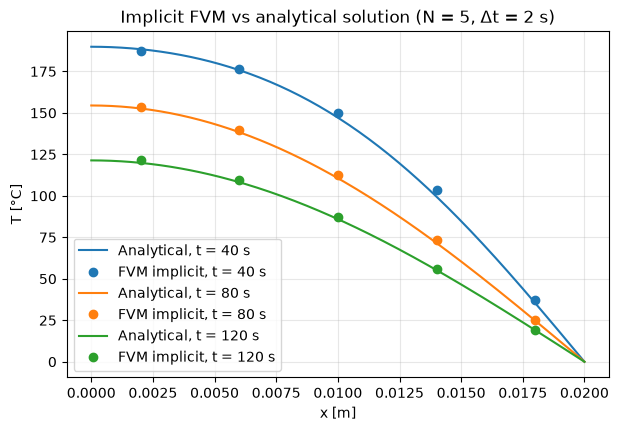

In [49]:
x_plot = np.linspace(0, 0.02, 200)
colors = ["C0", "C1", "C2"]

plt.figure(figsize=(7, 4.5))
for i in range(len(rod_history.frames)):
    t, T_num = rod_history.frames[i]
    T_exact = analytical_T(x_plot, t, L=0.02, alpha=10 / 1e7, n_terms=100)
    plt.plot(x_plot, T_exact, color=colors[i], label=f"Analytical, t = {t} s")
    plt.plot(xs, T_num, "o", color=colors[i], label=f"FVM implicit, t = {t} s")

plt.xlabel("x [m]")
plt.ylabel("T [°C]")
plt.title("Implicit FVM vs analytical solution (N = 5, Δt = 2 s)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

✅ **Submission requirement:** error calculation

Even though the plot looks close, we have to measure the accuracy. Same as Assignment 3, we compare the numerical $T_i$ with the analytical solution at the same node positions, and take the largest absolute difference at each time.
$$ E(t) = \max_i \left| T_i(t) - T(x_i, t) \right| $$

In [50]:

for i in range(len(rod_history.frames)):
    t, T_num = rod_history.frames[i]
    t_exact, T_exact = analytical_frames[i]
    error = np.max(np.abs(T_num - T_exact))
    print(f"t = {t} s: max error = {error:.2f} °C")

t = 40 s: max error = 4.19 °C
t = 80 s: max error = 1.75 °C
t = 120 s: max error = 1.65 °C


### $\Delta t = 4\,\mathrm{s}$ and $8\,\mathrm{s}$

The march is the same for the other two time steps, only `time_step` changes. So I make a new `ImplicitMarch` for each $\Delta t$, reset the field to $200\,{}^\circ\mathrm{C}$ and record. All the histories are stored in one list, in the same order as `time_steps`:

In [51]:
time_steps = [2, 4, 8]
histories = []
for dt in time_steps:
    march = ImplicitMarch(
        diffusion= rod_diffusion_term,
        transient= rod_transient_term,
        time_step= dt
    )
    rod_temp.reset()
    histories.append(march.record_run(t_end = 120, save_every = round(40 / dt)))

# Show recording
for i in range(len(time_steps)):
    print(f"Δt = {time_steps[i]} s")
    for frame in histories[i].frames:
        print(frame)

Δt = 2 s
(40, array([187.4199706 , 176.28746435, 150.03853232, 103.69795834,
        37.51391075]))
(80, array([153.71957546, 139.79036191, 112.38543759,  73.09455089,
        25.3882577 ]))
(120, array([121.52475979, 109.78757245,  87.33157778,  56.20119559,
        19.39350135]))
Δt = 4 s
(40, array([186.90167105, 176.19793773, 150.78523743, 105.14617738,
        38.40363271]))
(80, array([153.88307527, 140.14165689, 112.94000362,  73.63987016,
        25.61886081]))
(120, array([121.99410882, 110.25841663,  87.76648256,  56.52000315,
        19.51183024]))
Δt = 8 s
(40, array([186.00457166, 176.00667293, 152.07703773, 107.93528491,
        40.3938541 ]))
(80, array([154.16202572, 140.80923671, 114.05601748,  74.78291213,
        26.11562884]))
(120, array([122.88749251, 111.17796757,  88.6443155 ,  57.18049891,
        19.76039517]))


Now we plot all three, one plot for each $\Delta t$:

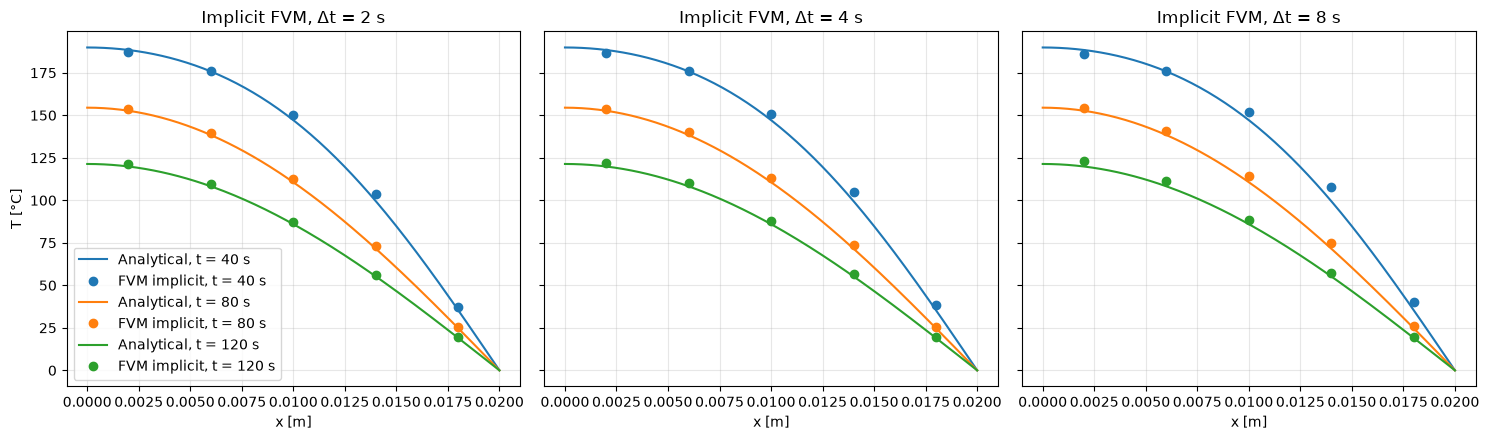

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for k in range(len(time_steps)):
    ax = axes[k]
    for i in range(len(histories[k].frames)):
        t, T_num = histories[k].frames[i]
        T_exact = analytical_T(x_plot, t, L=0.02, alpha=10 / 1e7, n_terms=100)
        ax.plot(x_plot, T_exact, color=colors[i], label=f"Analytical, t = {t} s")
        ax.plot(xs, T_num, "o", color=colors[i], label=f"FVM implicit, t = {t} s")
    ax.set_title(f"Implicit FVM, Δt = {time_steps[k]} s")
    ax.set_xlabel("x [m]")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("T [°C]")
axes[0].legend()
plt.tight_layout()
plt.show()

And the errors for every $\Delta t$:

In [53]:

print("Δt [s] | E(40 s) | E(80 s) | E(120 s)   [°C]")
for k in range(len(time_steps)):
    errors = []
    for i in range(len(histories[k].frames)):
        t, T_num = histories[k].frames[i]
        t_exact, T_exact = analytical_frames[i]
        errors.append(np.max(np.abs(T_num - T_exact)))
    print(f"{time_steps[k]:6} | {errors[0]:7.2f} | {errors[1]:7.2f} | {errors[2]:8.2f}")

Δt [s] | E(40 s) | E(80 s) | E(120 s)   [°C]
     2 |    4.19 |    1.75 |     1.65
     4 |    5.64 |    2.30 |     2.12
     8 |    8.43 |    3.42 |     3.01


### Explicit vs implicit at $\Delta t = 8\,\mathrm{s}$

From Assignment 3, the max time step for the explicit march is $5.33\,\mathrm{s}$. So $8\,\mathrm{s}$ is over the limit, and `ExplicitMarch.run()` will not run. I added `check_stability` to `ExplicitMarch`, setting it to `False` turns off the check so we can see what happens:

In [54]:

print(inspect.getsource(ExplicitMarch.__init__))

    def __init__(self, diffusion, transient, time_step, check_stability=True):  
        super().__init__(diffusion, transient, time_step)  
        #  False lets us march past the limit on purpose, to see what goes wrong
        self.check_stability = check_stability  



This time I save every step (`save_every = 1`), so we can also see what happens in between $40\,\mathrm{s}$, $80\,\mathrm{s}$ and $120\,\mathrm{s}$:

In [55]:

e_march_8 = ExplicitMarch(
    diffusion= rod_diffusion_term,
    transient= rod_transient_term,
    time_step= 8,
    check_stability= False
)
i_march_8 = ImplicitMarch(
    diffusion= rod_diffusion_term,
    transient= rod_transient_term,
    time_step= 8
)
rod_temp.reset()
e_history_8 = e_march_8.record_run(t_end = 120, save_every = 1)
rod_temp.reset()
i_history_8 = i_march_8.record_run(t_end = 120, save_every = 1)

# Show recording
print("Explicit:")
for frame in e_history_8.frames:
    print(frame)
print("Implicit:")
for frame in i_history_8.frames:
    print(frame)

Explicit:
(8, array([ 2.00000000e+02,  2.00000000e+02,  2.00000000e+02,  2.00000000e+02,
       -1.98951966e-13]))
(16, array([200., 200., 200., 100., 100.]))
(24, array([ 2.00000000e+02,  2.00000000e+02,  1.50000000e+02,  1.50000000e+02,
       -1.27897692e-13]))
(32, array([200., 175., 175.,  75.,  75.]))
(40, array([ 1.8750000e+02,  1.8750000e+02,  1.2500000e+02,  1.2500000e+02,
       -9.9475983e-14]))
(48, array([187.5 , 156.25, 156.25,  62.5 ,  62.5 ]))
(56, array([ 1.7187500e+02,  1.7187500e+02,  1.0937500e+02,  1.0937500e+02,
       -9.9475983e-14]))
(64, array([171.875 , 140.625 , 140.625 ,  54.6875,  54.6875]))
(72, array([ 1.56250000e+02,  1.56250000e+02,  9.76562500e+01,  9.76562500e+01,
       -7.81597009e-14]))
(80, array([156.25    , 126.953125, 126.953125,  48.828125,  48.828125]))
(88, array([ 1.41601562e+02,  1.41601562e+02,  8.78906250e+01,  8.78906250e+01,
       -7.10542736e-14]))
(96, array([141.6015625 , 114.74609375, 114.74609375,  43.9453125 ,
        43.945312

We plot the profiles at $40\,\mathrm{s}$, $80\,\mathrm{s}$ and $120\,\mathrm{s}$ by picking those times out of every step:

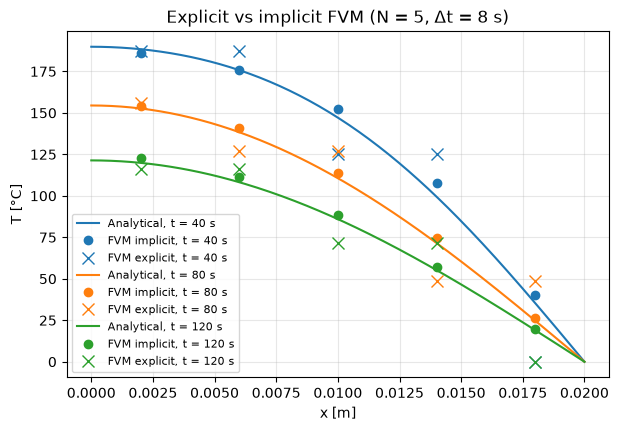

t = 40 s: max error explicit = 35.38 °C, implicit = 8.43 °C
t = 80 s: max error explicit = 24.05 °C, implicit = 3.42 °C
t = 120 s: max error explicit = 19.05 °C, implicit = 3.01 °C


In [56]:

plt.figure(figsize=(7, 4.5))
i = 0
for n in range(len(e_history_8.frames)):
    t, T_explicit = e_history_8.frames[n]
    if t in ts:
        t, T_implicit = i_history_8.frames[n]
        T_exact = analytical_T(x_plot, t, L=0.02, alpha=10 / 1e7, n_terms=100)
        plt.plot(x_plot, T_exact, color=colors[i], label=f"Analytical, t = {t} s")
        plt.plot(xs, T_implicit, "o", color=colors[i], label=f"FVM implicit, t = {t} s")
        plt.plot(xs, T_explicit, "x", color=colors[i], markersize=9, label=f"FVM explicit, t = {t} s")
        i += 1

plt.xlabel("x [m]")
plt.ylabel("T [°C]")
plt.title("Explicit vs implicit FVM (N = 5, Δt = 8 s)")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

for n in range(len(e_history_8.frames)):
    t, T_explicit = e_history_8.frames[n]
    if t in ts:
        t, T_implicit = i_history_8.frames[n]
        T_exact = analytical_T(xs, t, L=0.02, alpha=10 / 1e7, n_terms=100)
        e_error = np.max(np.abs(T_explicit - T_exact))
        i_error = np.max(np.abs(T_implicit - T_exact))
        print(f"t = {t} s: max error explicit = {e_error:.2f} °C, implicit = {i_error:.2f} °C")

The profiles only show three moments. To see what the explicit march does in between, I plot the node next to the cold wall, $T_5$, at every step:

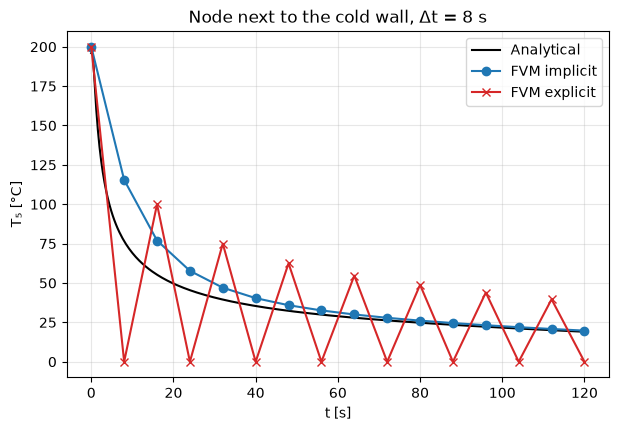

In [57]:

t_plot = np.linspace(0, 120, 300)
T5_exact = [analytical_T(xs[-1], t, L=0.02, alpha=10 / 1e7, n_terms=100) for t in t_plot]

e_times = [0] + [frame[0] for frame in e_history_8.frames]
e_T5 = [200] + [frame[1][-1] for frame in e_history_8.frames]
i_times = [0] + [frame[0] for frame in i_history_8.frames]
i_T5 = [200] + [frame[1][-1] for frame in i_history_8.frames]

plt.figure(figsize=(7, 4.5))
plt.plot(t_plot, T5_exact, color="k", label="Analytical")
plt.plot(i_times, i_T5, "o-", color="C0", label="FVM implicit")
plt.plot(e_times, e_T5, "x-", color="C3", label="FVM explicit")
plt.xlabel("t [s]")
plt.ylabel("T₅ [°C]")
plt.title("Node next to the cold wall, Δt = 8 s")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Discussion

✅ **Submission requirement:** brief discussion

- **Implicit gets less accurate with bigger $\Delta t$.** At $40\,\mathrm{s}$ the error is $4.19$, $5.64$ and $8.43\,{}^\circ\mathrm{C}$ for $\Delta t = 2, 4, 8\,\mathrm{s}$. The fully implicit scheme is only first order accurate in time, so a bigger time step means a bigger error. For every $\Delta t$ the largest error is at $40\,\mathrm{s}$, when the temperature changes the fastest, and it gets smaller at $80\,\mathrm{s}$ and $120\,\mathrm{s}$.
- **Explicit at $\Delta t = 8\,\mathrm{s}$ zigzags.** It doesn't blow up, but $T_5$ drops to $0\,{}^\circ\mathrm{C}$ every other step and jumps back up in between, which doesn't happen in the real plate. The error is $35.38$, $24.05$ and $19.05\,{}^\circ\mathrm{C}$ at $40$, $80$ and $120\,\mathrm{s}$, compared to $8.43$, $3.42$ and $3.01\,{}^\circ\mathrm{C}$ for implicit.

The zigzag comes from Patankar's positive-coefficient rule from Assignment 3. In the explicit march the coefficient of the old $T_5$ is
$$1 - \frac{\Delta t}{\rho c\,\Delta V}A_{55} = 1 - \frac{8}{400}\cdot 75 = -0.5$$
So a hot $T_5$ makes the next $T_5$ cold, and the other way around. The $5.33\,\mathrm{s}$ limit is where this coefficient becomes $0$. Past it the explicit solution is not physical anymore, even though here it still decays (the zigzag shrinks by about $0.95$ every step, it would only blow up above about $8.2\,\mathrm{s}$). For the implicit march, every diagonal of $\mathbf M$ is bigger than its off-diagonals for any $\Delta t$, so the solution stays smooth.

Thus the implicit march lets us use bigger time steps and still stay physical, but we have to solve a tridiagonal system every step, and the accuracy still depends on $\Delta t$.